**CLAP** (*Contrastive Language-Audio Pretraining*, `laion/clap-htsat-unfused`, Wu et al. 2023, ~150 M de paramètres) contient deux parties entraînées ensemble : un **encodeur audio** et un **encodeur de texte**. Il a appris sur des millions de paires « son + description » à donner des vecteurs proches (512 nombres) à un son et à la phrase qui le décrit.

Notre analyse porte uniquement sur l'audio: les représentations utilisées sont celles du **son** des extraits.

Dans ce notebook, on va tester CLAP de deux façons :
1. **Sans entraînement (zero-shot)** : on compare le son de chaque extrait à de courtes phrases que nous avons écrites pour décrire les 8 émotions (« a scary scene »…), sans utiliser aucun exemple annoté.
2. **Avec le classifieur commun** : vecteur audio CLAP + régression logistique, comme pour AST (b1).

Puis on mesure si CLAP **complète AST**, l'autre modèle de sons généraux (fusions audio uniquement).


## 0. Préparation

In [1]:
import sys
from pathlib import Path

if "google.colab" in sys.modules:
    from google.colab import drive
    drive.mount("/content/drive")
    CODE = Path("/content/drive/MyDrive/Projet Multimédia/Partie audio/ghislain")
else:
    CODE = next(p for p in [Path.cwd(), *Path.cwd().parents]
                if (p / "audio" / "ghislain" / "utils.py").exists()) / "audio" / "ghislain"
sys.path.insert(0, str(CODE))

import importlib
import utils
importlib.reload(utils)

P = utils.setup()            # audio + annotations

Mounted at /content/drive
Copie du zip depuis le Drive (~2-3 min)...
$ cp "/content/drive/MyDrive/Projet Multimédia/PROJET_SID_2026.zip" /content/PROJET_SID_2026.zip
Décompression de : audio, annotation
$ mkdir -p /content/data && unzip -q -o /content/PROJET_SID_2026.zip 'PROJET_SID_2026/movie/audio/*' 'PROJET_SID_2026/movie/annotation/*' -d /content/data
Données  : /content/data/PROJET_SID_2026
Résultats: /content/drive/MyDrive/Projet Multimédia/Partie audio/ghislain


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Test rapide : mettre par ex. 20 (extraits par ensemble). None = tous les extraits.
ECHANTILLON = None

meta = utils.load_metadata(P)
SUFFIXE = ""
if ECHANTILLON:
    meta = (pd.concat([meta[meta.split == s].sample(ECHANTILLON, random_state=utils.SEED)
                       for s in utils.SPLITS]).sort_values("video_id").reset_index(drop=True))
    SUFFIXE = "_echantillon"
tr, dv, te = (meta.split == s for s in utils.SPLITS)
y = meta.label.to_numpy()
print(len(meta), "extraits |", meta.split.value_counts().to_dict())

3088 extraits | {'train': 2207, 'dev': 442, 'test': 439}


## 1. Extraction des représentations CLAP

CLAP attend un audio à **48 kHz** et traite au plus **10 secondes**. Au-delà, il en coupe un morceau **au hasard**, ce qui rendrait les résultats non reproductibles : on découpe donc nous-mêmes chaque extrait en fenêtres de même longueur (≤ 10 s) et on fait la moyenne de leurs vecteurs.

In [3]:
import inspect
import torch
from transformers import ClapModel, ClapProcessor

MODEL_ID = "laion/clap-htsat-unfused"
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
SR, WIN, BATCH = 48000, 10 * 48000, 16

processeur = ClapProcessor.from_pretrained(MODEL_ID)
clap = ClapModel.from_pretrained(MODEL_ID).to(DEVICE).eval()
# Compatibilité entre versions de transformers (argument 'audio' ou 'audios', sortie tenseur ou objet)
ARG_AUDIO = "audio" if "audio" in inspect.signature(processeur.__call__).parameters else "audios"
vecteur = lambda sortie: sortie.pooler_output if hasattr(sortie, "pooler_output") else sortie
print("Calcul sur", DEVICE, "| paramètres :", round(sum(p.numel() for p in clap.parameters()) / 1e6), "M")


@torch.no_grad()
def vecteurs_clap(chemins):
    fenetres, proprietaire = [], []
    for i, c in enumerate(chemins):
        son = utils.load_audio(c, SR)
        n = max(1, int(np.ceil(len(son) / WIN)))
        for morceau in np.array_split(son, n):
            fenetres.append(morceau)
            proprietaire.append(i)
    embs = []
    for b in range(0, len(fenetres), BATCH):
        x = processeur(**{ARG_AUDIO: fenetres[b:b + BATCH]}, sampling_rate=SR, return_tensors="pt").to(DEVICE)
        embs.append(vecteur(clap.get_audio_features(**x)).cpu().numpy())
    embs, proprietaire = np.concatenate(embs), np.array(proprietaire)
    out = np.stack([embs[proprietaire == i].mean(0) for i in range(len(chemins))])
    return out / np.linalg.norm(out, axis=1, keepdims=True)      # vecteurs normés (comparaison cosinus)


@torch.no_grad()
def vecteurs_texte(textes):
    embs = []
    for b in range(0, len(textes), 64):
        x = processeur(text=list(textes[b:b + 64]), return_tensors="pt", padding=True, truncation=True).to(DEVICE)
        embs.append(vecteur(clap.get_text_features(**x)).cpu().numpy())
    e = np.concatenate(embs)
    return e / np.linalg.norm(e, axis=1, keepdims=True)


X_clap = utils.extract_features("clap" + SUFFIXE, meta, vecteurs_clap, P)
print("vecteurs CLAP :", X_clap.shape)

preprocessor_config.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/5.39k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/384 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/798k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.11M [00:00<?, ?B/s]

... (5 outputs left out)

model.safetensors: downloading bytes:           |  0.00B            

Calcul sur cuda | paramètres : 153 M


extraction clap:   0%|          | 0/16 [00:00<?, ?it/s]

vecteurs CLAP : (3088, 512)


## 2. CLAP sans entraînement (zero-shot)

Pour chaque émotion, on écrit plusieurs phrases (« a scary scene in a movie », « the soundtrack of a scary moment »…) et on fait la moyenne de leurs vecteurs. Chaque extrait reçoit l'émotion dont la description est la **plus proche** de son vecteur **audio**. **Aucun exemple annoté n'est utilisé** : on mesure ce que le modèle « sait » déjà.

Les phrases ne sont **pas des données** du corpus : ce sont seulement les noms des 8 émotions mis sous forme de phrases. Ce qui est analysé, c'est uniquement le **son** de chaque extrait.

Deux variantes : **brute**, et **calibrée** (on retire à chaque émotion sa similarité moyenne sur les sons du train, sans leurs étiquettes, pour corriger le biais d'une phrase plus « attirante » que les autres).

[clap_zeroshot | dev] F1 macro = 0.066 | acc. équilibrée = 0.127 | accuracy = 0.104
   F1 macro avec parole = 0.034 | sans parole = 0.105
   F1 par émotion : amusement 0.15, awe 0.00, contentment 0.03, excitement 0.00, anger 0.15, disgust 0.02, fear 0.14, sadness 0.04
[clap_zeroshot | test] F1 macro = 0.059 | acc. équilibrée = 0.124 | accuracy = 0.091
   F1 macro avec parole = 0.021 | sans parole = 0.104
   F1 par émotion : amusement 0.15, awe 0.04, contentment 0.07, excitement 0.00, anger 0.02, disgust 0.00, fear 0.15, sadness 0.04
   prédictions (test) : {'amusement': 348, 'disgust': 32, 'anger': 30, 'fear': 17, 'awe': 6, 'contentment': 5, 'sadness': 1} 

[clap_zeroshot_calibre | dev] F1 macro = 0.140 | acc. équilibrée = 0.154 | accuracy = 0.161
   F1 macro avec parole = 0.094 | sans parole = 0.171
   F1 par émotion : amusement 0.15, awe 0.00, contentment 0.20, excitement 0.07, anger 0.25, disgust 0.08, fear 0.19, sadness 0.18
[clap_zeroshot_calibre | test] F1 macro = 0.160 | acc. éq

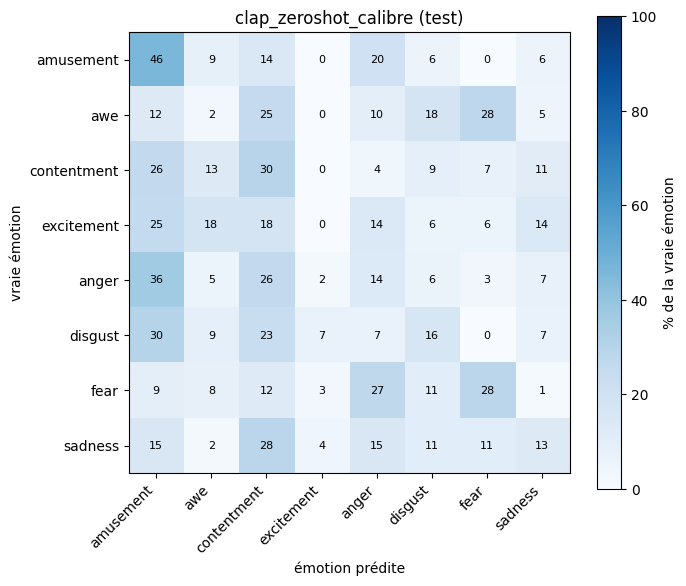

In [4]:
ADJECTIFS = {"amusement": "funny", "awe": "awe-inspiring", "contentment": "peaceful",
             "excitement": "exciting", "anger": "angry", "disgust": "disgusting",
             "fear": "scary", "sadness": "sad"}
MODELES_PHRASES = ["a {} scene in a movie", "the soundtrack of a {} moment",
                   "{} sounds and music", "a movie scene that feels {}"]

T = []
for e in utils.EMOTIONS:
    v = vecteurs_texte([m.format(ADJECTIFS[e]) for m in MODELES_PHRASES]).mean(0)
    T.append(v / np.linalg.norm(v))
T = np.stack(T)                                             # (8, 512)

ECHELLE = float(clap.logit_scale_a.detach().exp())                # « température » apprise par CLAP
logits = ECHELLE * X_clap @ T.T


def softmax(z):
    z = np.exp(z - z.max(1, keepdims=True))
    return z / z.sum(1, keepdims=True)


# Version calibrée : certaines phrases sont plus proches de TOUS les sons (biais). On retire à chaque
# émotion sa similarité moyenne sur les extraits du train, SANS utiliser leurs étiquettes.
variantes = {"clap_zeroshot": softmax(logits),
             "clap_zeroshot_calibre": softmax(logits - logits[tr].mean(0))}
for nom, proba_zs in variantes.items():
    nom += SUFFIXE
    for split, m in (("dev", dv), ("test", te)):
        utils.log_results(utils.evaluate(y[m], proba_zs[m], meta.parole[m], nom, split), P)
        utils.save_preds(meta.video_id[m], proba_zs[m], nom, split, P)
    print("   prédictions (test) :",
          pd.Series(np.array(utils.EMOTIONS)[proba_zs[te].argmax(1)]).value_counts().to_dict(), "\n")
utils.plot_confusion(y[te], variantes["clap_zeroshot_calibre"][te], f"clap_zeroshot_calibre{SUFFIXE} (test)",
                     P, f"cm_clap_zeroshot_calibre{SUFFIXE}_test.png")
plt.show()

## 3. CLAP avec le classifieur commun

Même procédure que pour AST : vecteur CLAP (512 nombres) → régression logistique pondérée, `C` choisi sur le **dev**, mesure finale sur le **test**.


=== clap (C = 0.0001)
[clap | dev] F1 macro = 0.257 | acc. équilibrée = 0.269 | accuracy = 0.267
   F1 macro avec parole = 0.241 | sans parole = 0.202
   F1 par émotion : amusement 0.26, awe 0.15, contentment 0.32, excitement 0.27, anger 0.25, disgust 0.11, fear 0.36, sadness 0.35
[clap | test] F1 macro = 0.221 | acc. équilibrée = 0.240 | accuracy = 0.239
   F1 macro avec parole = 0.196 | sans parole = 0.196
   F1 par émotion : amusement 0.35, awe 0.13, contentment 0.23, excitement 0.17, anger 0.24, disgust 0.07, fear 0.40, sadness 0.19


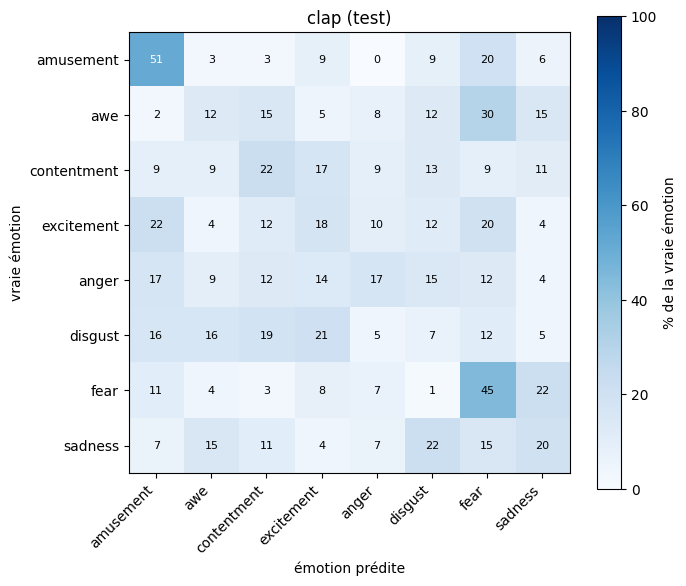

In [5]:
def evaluer(nom, X):
    clf, C, _ = utils.select_C(X[tr], y[tr], X[dv], y[dv])
    print(f"\n=== {nom} (C = {C})")
    probas = {}
    for split, m in (("dev", dv), ("test", te)):
        probas[split] = clf.predict_proba(X[m])
        utils.log_results(utils.evaluate(y[m], probas[split], meta.parole[m], nom, split), P)
        utils.save_preds(meta.video_id[m], probas[split], nom, split, P)
    return probas


p_clap = evaluer("clap" + SUFFIXE, X_clap)
utils.plot_confusion(y[te], p_clap["test"], f"clap{SUFFIXE} (test)", P, f"cm_clap{SUFFIXE}_test.png")
plt.show()

## 4. CLAP complète-t-il AST ?

AST et CLAP sont deux modèles de **sons généraux**. On vérifie si les combiner fait mieux qu'AST seul :
- **fusion précoce** : on met bout à bout les deux vecteurs (768 + 512 nombres) avant le classifieur ;
- **fusion tardive** : on fait la moyenne pondérée des probabilités des deux classifieurs, avec des poids choisis sur le **dev**.

In [6]:
Z = utils.load_features("ast" + SUFFIXE, P, meta.video_id.tolist())
X_ast = Z[:, :768]

p_ast = evaluer("ast" + SUFFIXE, X_ast)
evaluer("fus_precoce_ast_clap" + SUFFIXE, np.hstack([X_ast, X_clap]))

poids, f1_dev = utils.select_weights([p_ast["dev"], p_clap["dev"]], y[dv])
print(f"\n=== fus_tardive_ast_clap : poids AST {poids[0]} / CLAP {poids[1]} (F1 macro dev = {f1_dev:.3f})")
for split, m in (("dev", dv), ("test", te)):
    proba = utils.fuse([p_ast[split], p_clap[split]], poids)
    utils.log_results(utils.evaluate(y[m], proba, meta.parole[m], "fus_tardive_ast_clap" + SUFFIXE, split), P)
    utils.save_preds(meta.video_id[m], proba, "fus_tardive_ast_clap" + SUFFIXE, split, P)


=== ast (C = 0.0001)
[ast | dev] F1 macro = 0.236 | acc. équilibrée = 0.253 | accuracy = 0.242
   F1 macro avec parole = 0.231 | sans parole = 0.175
   F1 par émotion : amusement 0.27, awe 0.23, contentment 0.15, excitement 0.22, anger 0.23, disgust 0.13, fear 0.31, sadness 0.35
[ast | test] F1 macro = 0.248 | acc. équilibrée = 0.269 | accuracy = 0.271
   F1 macro avec parole = 0.259 | sans parole = 0.175
   F1 par émotion : amusement 0.32, awe 0.14, contentment 0.23, excitement 0.19, anger 0.26, disgust 0.16, fear 0.46, sadness 0.22

=== fus_precoce_ast_clap (C = 0.003)
[fus_precoce_ast_clap | dev] F1 macro = 0.273 | acc. équilibrée = 0.277 | accuracy = 0.274
   F1 macro avec parole = 0.245 | sans parole = 0.261
   F1 par émotion : amusement 0.33, awe 0.20, contentment 0.26, excitement 0.26, anger 0.32, disgust 0.05, fear 0.29, sadness 0.46
[fus_precoce_ast_clap | test] F1 macro = 0.239 | acc. équilibrée = 0.245 | accuracy = 0.255
   F1 macro avec parole = 0.218 | sans parole = 0.216

## 5. Comparaison

f1_macro        f1_macro_avec_parole         \
split                      dev   test                  dev   test   
modele                                                              
hasard_stratifie         0.102  0.134                0.102  0.146   
clap_zeroshot            0.066  0.059                0.034  0.021   
clap_zeroshot_calibre    0.140  0.160                0.094  0.115   
ast                      0.236  0.248                0.231  0.259   
clap                     0.257  0.221                0.241  0.196   
fus_tardive_ast_clap     0.272  0.240                0.267  0.241   
fus_precoce_ast_clap     0.273  0.239                0.245  0.218   

                      f1_macro_sans_parole         
split                                  dev   test  
modele                                             
hasard_stratifie                     0.099  0.096  
clap_zeroshot                        0.105  0.104  
clap_zeroshot_calibre                0.171  0.237  
ast                                  0.175  0.175  
clap                                 0.202  0.196  
fus_tardive_ast_clap                 0.170  0.184  
fus_precoce_ast_clap                 0.261  0.216

F1 par émotion (test) :


,amusement,awe,contentment,excitement,anger,disgust,fear,sadness
modele,,,,,,,,
hasard_stratifie,0.05,0.08,0.09,0.15,0.25,0.10,0.17,0.18
clap_zeroshot,0.15,0.04,0.07,0.00,0.02,0.00,0.15,0.04
clap_zeroshot_calibre,0.22,0.03,0.21,0.00,0.16,0.16,0.35,0.15
ast,0.32,0.14,0.23,0.19,0.26,0.16,0.46,0.22
clap,0.35,0.13,0.23,0.17,0.24,0.07,0.40,0.19
fus_tardive_ast_clap,0.34,0.17,0.23,0.24,0.24,0.12,0.41,0.17
fus_precoce_ast_clap,0.38,0.17,0.24,0.18,0.35,0.07,0.38,0.15


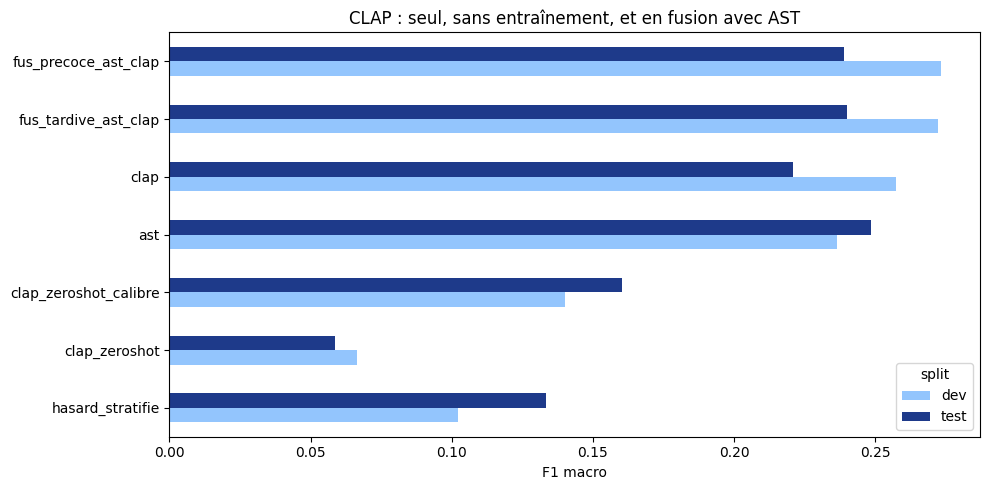

In [7]:
res = pd.read_csv(P.OUT / "resultats.csv")
noms = ["hasard_stratifie", "clap_zeroshot", "clap_zeroshot_calibre", "ast", "clap", "fus_tardive_ast_clap",
        "fus_precoce_ast_clap"]
noms = [n if n == "hasard_stratifie" else n + SUFFIXE for n in noms]
noms = [n for n in noms if n in set(res.modele)]
tab = (res[res.modele.isin(noms)]
       .pivot_table(index="modele", columns="split",
                    values=["f1_macro", "f1_macro_avec_parole", "f1_macro_sans_parole"])
       .reindex(noms).round(3))
display(tab)

cols = [f"f1_{e}" for e in utils.EMOTIONS]
emo = res[(res.split == "test") & res.modele.isin(noms)].set_index("modele")[cols].reindex(noms)
emo.columns = utils.EMOTIONS
print("F1 par émotion (test) :")
display(emo.round(2))

fig, ax = plt.subplots(figsize=(10, 5))
f1 = res[res.modele.isin(noms)].pivot(index="modele", columns="split", values="f1_macro").reindex(noms)
f1[["dev", "test"]].plot.barh(ax=ax, color=["#93c5fd", "#1e3a8a"])
ax.set(xlabel="F1 macro", ylabel="", title="CLAP : seul, sans entraînement, et en fusion avec AST")
fig.tight_layout()
fig.savefig(P.FIGS / f"clap_comparaison{SUFFIXE}.png", dpi=150)
plt.show()

## 6. Conclusion

**Zero-shot : CLAP ne reconnaît que faiblement les émotions sans entraînement.**
- Sans calibration, CLAP fait **moins bien que le hasard** (F1 macro 0,066 en dev, 0,059 en test) : il prédit `amusement` pour 79 % des extraits du test (348 sur 439), car la phrase « funny » est plus proche de tous les sons que les autres.
- Après calibration (sans utiliser les étiquettes), le F1 macro monte à **0,14 (dev) et 0,16 (test)**, à peine au-dessus du hasard (0,10 et 0,13). Les prédictions se répartissent alors sur toutes les émotions.
- L'émotion la mieux reconnue est **`fear` (F1 0,35)**, devant `amusement` (0,22) et `contentment` (0,21) ; `excitement` (0,00) et `awe` (0,03) ne sont pas reconnues.
- Le zero-shot marche mieux **sans parole** (0,24) qu'**avec parole** (0,12) : CLAP associe surtout l'émotion à la **musique et à l'ambiance sonore**, pas aux dialogues.

**CLAP + classifieur : proche d'AST, un peu meilleur sur le dev mais moins bon sur le test.**
- Sur le dev, CLAP fait **0,257** contre **0,236** pour AST ; sur le test, il fait **0,221** contre **0,248**. L'avantage du dev ne se retrouve donc pas sur le test.
- CLAP reconnaît surtout `fear` (0,40) et `amusement` (0,35) sur le test, mais très mal `disgust` (0,07).
- Apprendre le son à partir du langage (CLAP) n'apporte donc pas d'avantage net par rapport à l'apprendre à partir de catégories de sons (AST).

**Fusion : CLAP n'apporte rien en plus d'AST.**
- **Fusion précoce AST + CLAP** : meilleure qu'AST seul sur le dev (0,273 contre 0,236), mais **moins bonne sur le test** (0,239 contre 0,248).
- **Fusion tardive AST + CLAP** (poids 0,5 / 0,5 choisis sur le dev) : même constat, 0,272 sur le dev mais **0,240** sur le test.
- Les écarts sur le test restent dans la marge d'erreur (environ ±0,03 à ±0,05), mais aucune fusion ne dépasse AST seul.
- Explication : AST et CLAP sont deux modèles de **sons généraux** entraînés sur des données proches. Ils captent en grande partie la **même information**, donc CLAP est en majorité **redondant** avec AST.

**Bilan :** parmi les modèles de sons généraux, **AST reste la référence** (F1 macro de 0,248 sur le test). CLAP fait à peu près aussi bien seul, mais ne complète pas AST. Son apport principal est **explicatif** : le zero-shot montre que l'émotion se lit mieux dans l'ambiance sonore (musique, bruitages) que dans la parole.